Googlo colab上で計算させるためのコード

基本的には上から実行

In [ ]:
print("test")

test


In [2]:

# Colabに接続 mount
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import torch

print("----------------------------------------")
print("1. PyTorchバージョン:", torch.__version__)
print("2. GPUが利用可能か  :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("3. 使用中のGPU名   :", torch.cuda.get_device_name(0))
    print("★ 成功！Colab の GPU サーバーに正しく接続されています。")
else:
    print("⚠️ 注意: まだ PC ローカル（CPU）の環境で動いています。")
print("----------------------------------------")


----------------------------------------
1. PyTorchバージョン: 2.14.1+cu130
2. GPUが利用可能か  : True
3. 使用中のGPU名   : Tesla T4
★ 成功！Colab の GPU サーバーに正しく接続されています。
----------------------------------------


In [8]:
import os
print("現在の場所:", os.getcwd())
!ls 

現在の場所: /content/drive/MyDrive/Colab Notebooks/CNN_Image_Classification
CNN_pytorch_ResNet.py  CNN_pytorch_VGG11.py  data


In [14]:
# 対象ファイルの場所まで移動
%cd /content/drive/MyDrive/Colab Notebooks/CNN_Image_Classification/

!ls 

/content/drive/MyDrive/Colab Notebooks/CNN_Image_Classification
CNN_pytorch_MobileNet_finetune.py  CNN_pytorch_ResNet.py  data
CNN_pytorch_ResNet_finetune.py	   CNN_pytorch_VGG11.py


使用デバイス: cuda
総データ数: 160枚
検出されたクラス (6種類): ['good', 'manipulated_front', 'scratch_head', 'scratch_neck', 'thread_side', 'thread_top']


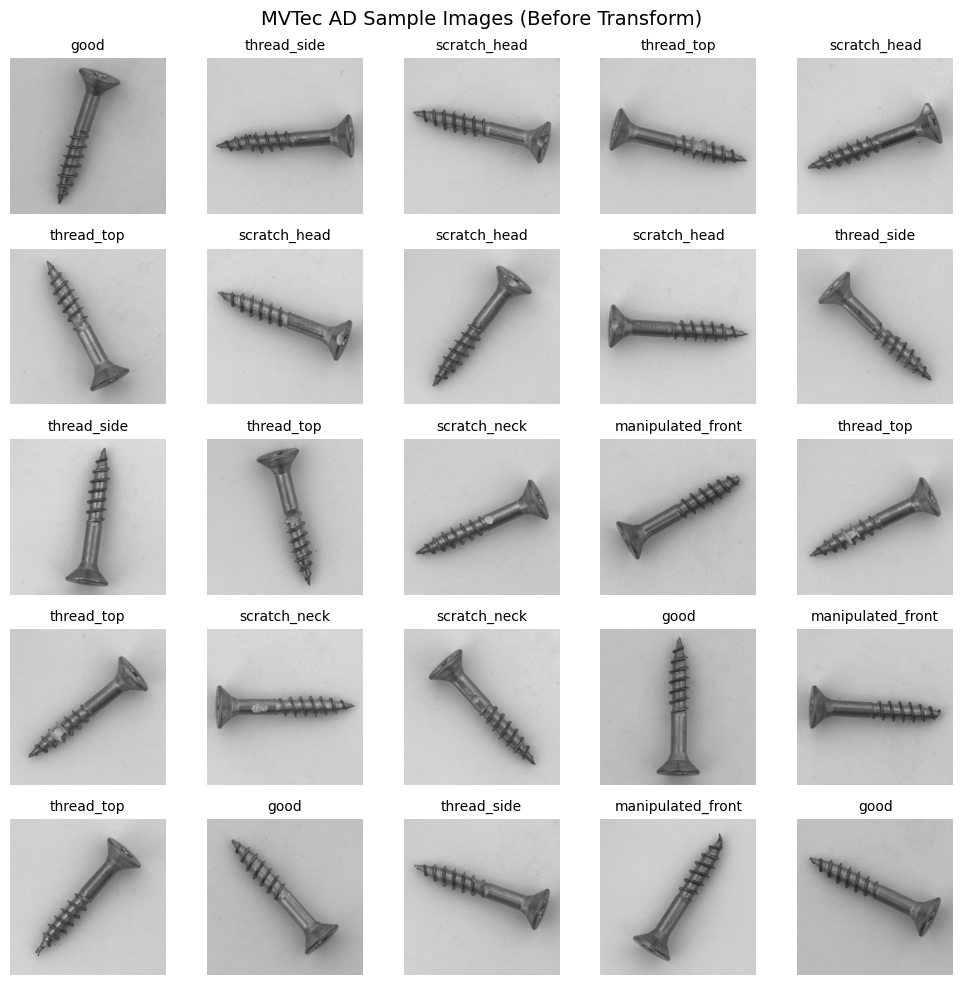

学習データ数: 128枚 / テストデータ数: 32枚
--- 読み込んだモデルの構造 ---
MobileNetV2(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 96, k

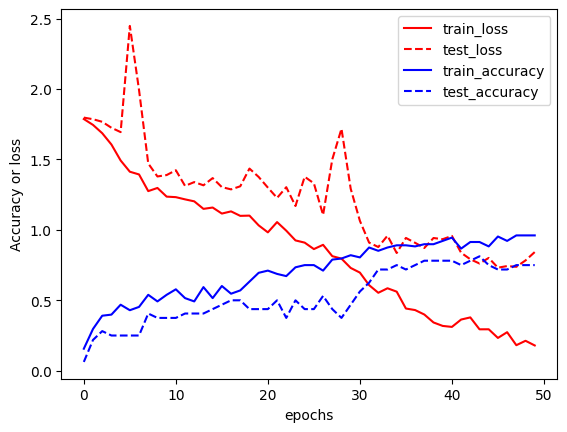

final test accuracy: 0.75

--- クラスごとの詳細な分類レポート ---
                   precision    recall  f1-score   support

             good       0.89      1.00      0.94         8
manipulated_front       0.80      0.80      0.80         5
     scratch_head       0.67      0.40      0.50         5
     scratch_neck       0.80      0.80      0.80         5
      thread_side       0.40      0.40      0.40         5
       thread_top       0.80      1.00      0.89         4

         accuracy                           0.75        32
        macro avg       0.73      0.73      0.72        32
     weighted avg       0.74      0.75      0.74        32



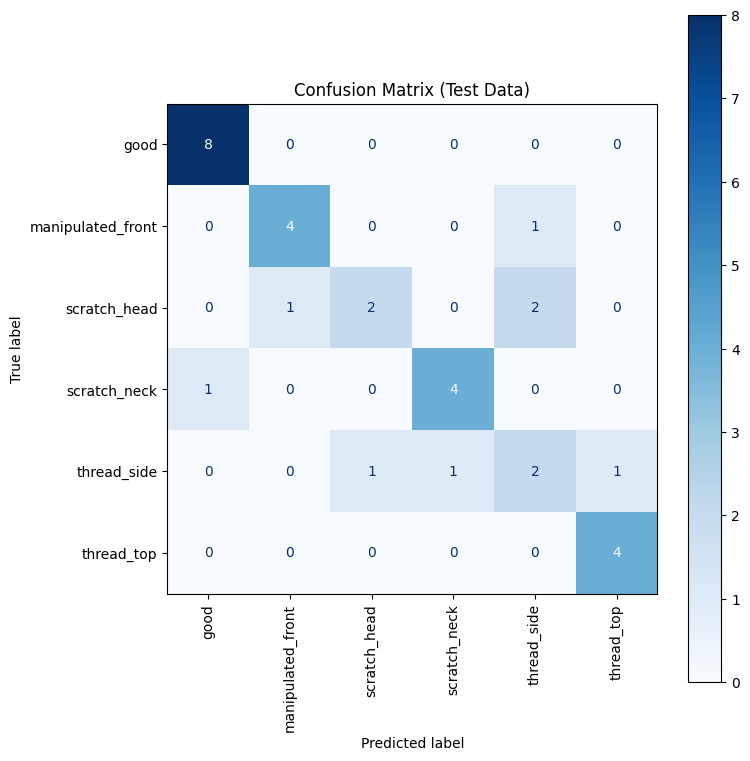

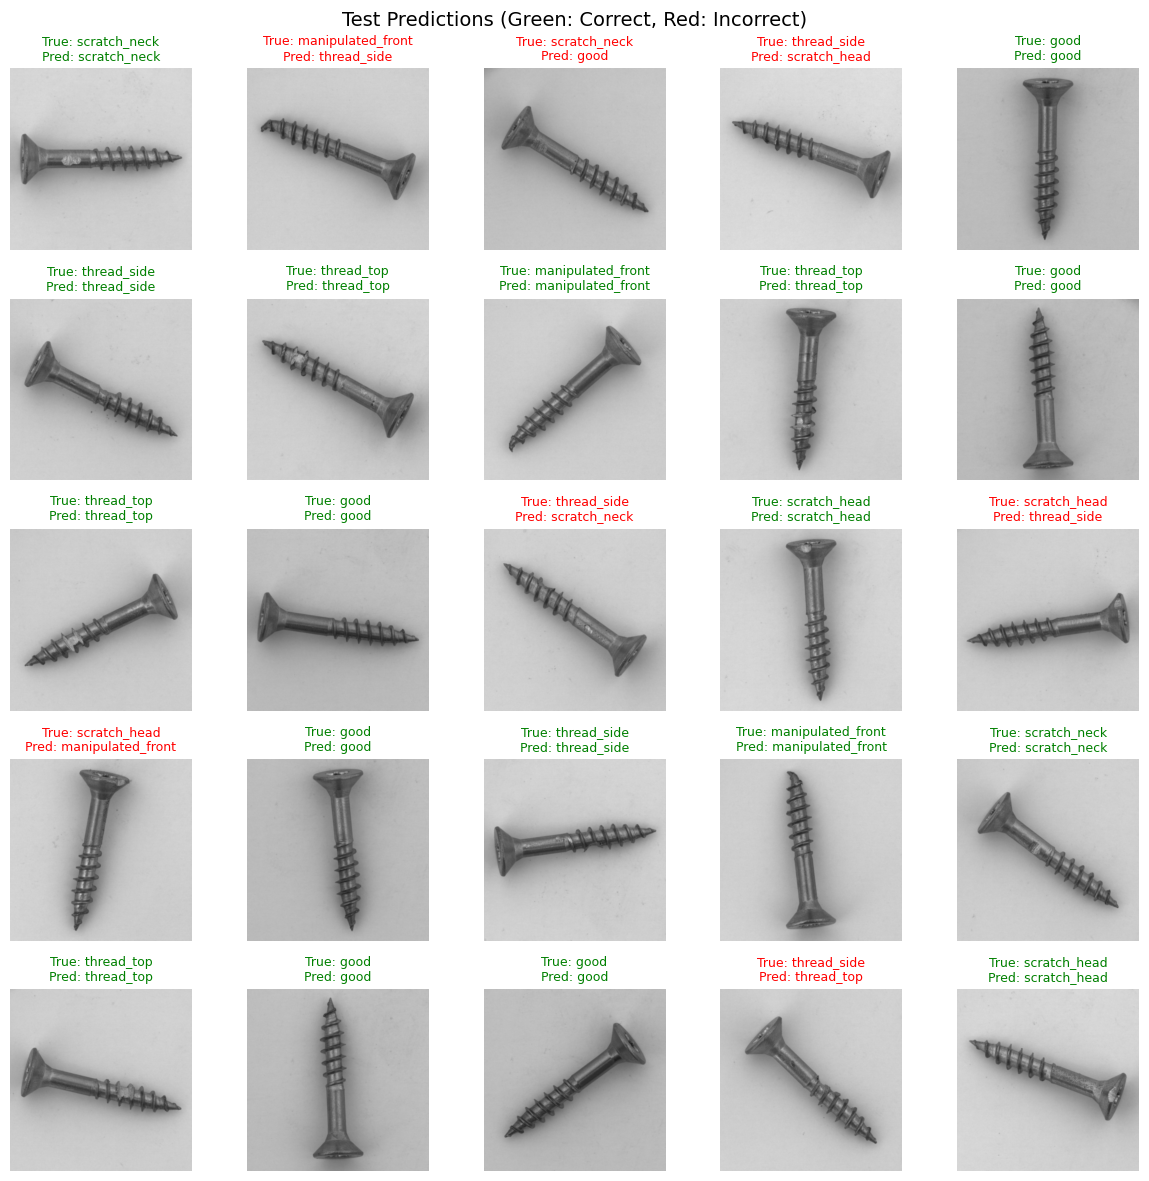

<Figure size 640x480 with 0 Axes>

In [19]:
# 実行
%run CNN_pytorch_MobileNet_finetune.py